In [30]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [31]:
df = pd.read_csv("CC GENERAL.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (8950, 18)

Columns:
['CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [32]:
df = pd.read_csv("CC GENERAL.csv")

features = df[["BALANCE", "PURCHASES"]].copy()

data = pd.concat(
    [features, df[["CREDIT_LIMIT"]]],
    axis=1
)

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna()

print("Dataset shape:", data.shape)
print(data.head())

Dataset shape: (8949, 3)
       BALANCE  PURCHASES  CREDIT_LIMIT
0    40.900749      95.40        1000.0
1  3202.467416       0.00        7000.0
2  2495.148862     773.17        7500.0
3  1666.670542    1499.00        7500.0
4   817.714335      16.00        1200.0


In [33]:
credit_threshold = data["CREDIT_LIMIT"].quantile(0.70)
purchase_threshold = data["PURCHASES"].quantile(0.70)

data["CLASS"] = (
    (data["CREDIT_LIMIT"] >= credit_threshold) &
    (data["PURCHASES"] >= purchase_threshold)
).astype(int)

print("Credit limit 70th percentile:", credit_threshold)
print("Purchase amount 70th percentile:", purchase_threshold)

print("\nClass counts:")
print(data["CLASS"].value_counts().sort_index())

print("\nClass percentages:")
print((data["CLASS"].value_counts(normalize=True).sort_index() * 100).round(2))

Credit limit 70th percentile: 6000.0
Purchase amount 70th percentile: 894.3519999999999

Class counts:
CLASS
0    7671
1    1278
Name: count, dtype: int64

Class percentages:
CLASS
0    85.72
1    14.28
Name: proportion, dtype: float64


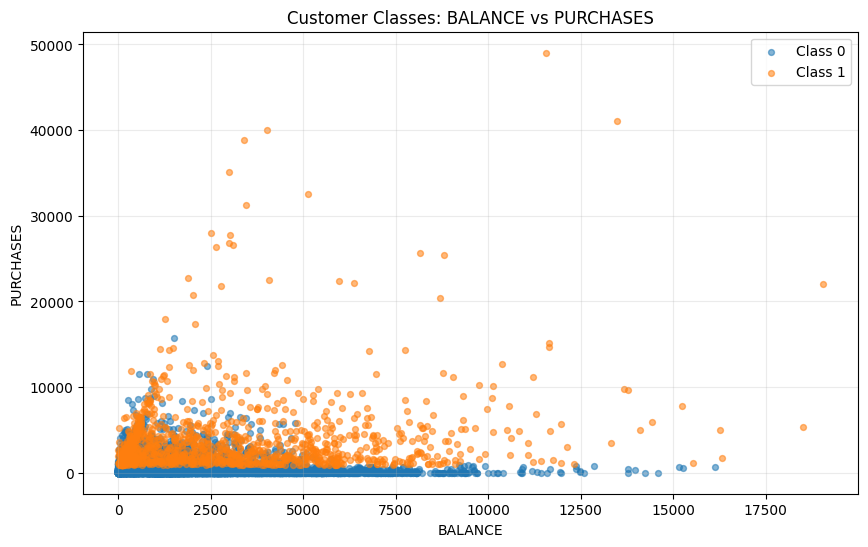

In [34]:
plt.figure(figsize=(10, 6))

for class_value, class_name in [(0, "Class 0"), (1, "Class 1")]:
    subset = data[data["CLASS"] == class_value]

    plt.scatter(
        subset["BALANCE"],
        subset["PURCHASES"],
        label=class_name,
        alpha=0.55,
        s=18
    )

plt.xlabel("BALANCE")
plt.ylabel("PURCHASES")
plt.title("Customer Classes: BALANCE vs PURCHASES")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [39]:



features = df[["BALANCE", "PURCHASES"]].copy()

features = features.replace([np.inf, -np.inf], np.nan)
valid_mask = features.notna().all(axis=1)

features = features.loc[valid_mask].copy()

boundary_slope = 0.5
boundary_intercept = 1000
gap = 1000

distance_from_boundary = (
    features["PURCHASES"]
    - boundary_slope * features["BALANCE"]
    - boundary_intercept
)

class_0_mask = distance_from_boundary <= -gap
class_1_mask = distance_from_boundary >= gap

keep_mask = class_0_mask | class_1_mask

filtered_features = features.loc[keep_mask].copy()

filtered_classes = np.where(
    class_1_mask.loc[keep_mask],
    1,
    -1
)

X_raw = filtered_features[
    ["BALANCE", "PURCHASES"]
].to_numpy()

y = filtered_classes

print("Filtered data shape:", X_raw.shape)
print("Class 0:", np.sum(y == -1))
print("Class 1:", np.sum(y == 1))
print("Minimum distance from chosen boundary:", gap)


Filtered data shape: (4980, 2)
Class 0: 4144
Class 1: 836
Minimum distance from chosen boundary: 1000


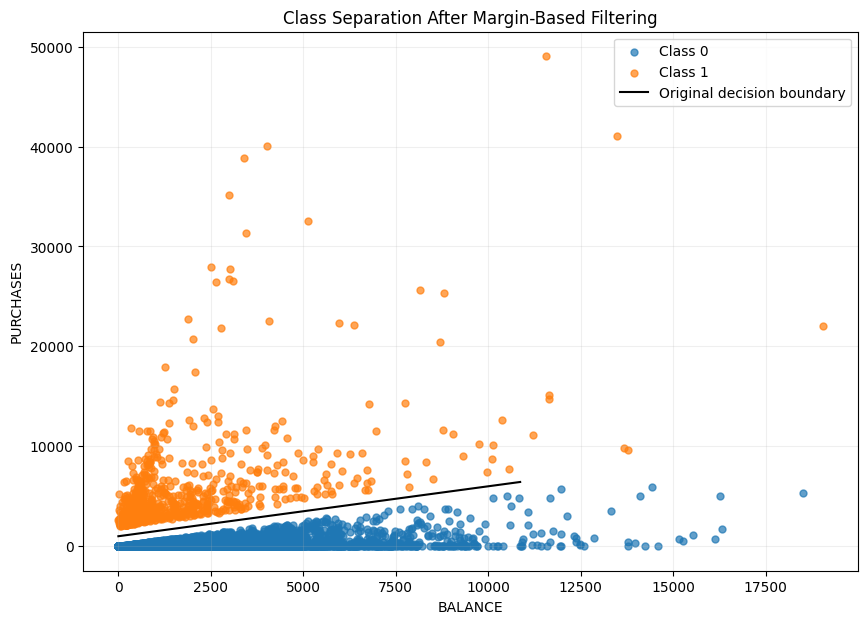

In [40]:

plt.figure(figsize=(10, 7))

plt.scatter(
    X_raw[y == -1, 0],
    X_raw[y == -1, 1],
    label="Class 0",
    alpha=0.7,
    s=25
)

plt.scatter(
    X_raw[y == 1, 0],
    X_raw[y == 1, 1],
    label="Class 1",
    alpha=0.7,
    s=25
)

balance_line = np.linspace(
    0,
    np.percentile(X_raw[:, 0], 99),
    300
)

purchases_line = (
    boundary_slope * balance_line
    + boundary_intercept
)

plt.plot(
    balance_line,
    purchases_line,
    color="black",
    label="Original decision boundary"
)

plt.xlabel("BALANCE")
plt.ylabel("PURCHASES")
plt.title("Class Separation After Margin-Based Filtering")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [43]:
samples_per_class = 250

class_0 = data[data["CLASS"] == 0]
class_1 = data[data["CLASS"] == 1]

sample_size = min(
    samples_per_class,
    len(class_0),
    len(class_1)
)

sample_0 = class_0.sample(n=sample_size, random_state=42)
sample_1 = class_1.sample(n=sample_size, random_state=42)

sampled_data = pd.concat(
    [sample_0, sample_1]
).sample(frac=1, random_state=42).reset_index(drop=True)

X_raw = sampled_data[["BALANCE", "PURCHASES"]].to_numpy()
y_original = sampled_data["CLASS"].to_numpy()

scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

y = np.where(y_original == 1, 1.0, -1.0)

print("Samples used for manual SVM:", len(sampled_data))
print("Class counts:")
print(sampled_data["CLASS"].value_counts().sort_index())

Samples used for manual SVM: 500
Class counts:
CLASS
0    250
1    250
Name: count, dtype: int64


In [44]:
from scipy.optimize import minimize
def dual_objective(alpha, X, y):
    kernel_matrix = X @ X.T
    Q = np.outer(y, y) * kernel_matrix

    return 0.5 * alpha @ Q @ alpha - np.sum(alpha)


def dual_gradient(alpha, X, y):
    kernel_matrix = X @ X.T
    Q = np.outer(y, y) * kernel_matrix

    return Q @ alpha - np.ones(len(y))


def train_manual_svm(X, y, C):
    n_samples = len(y)

    initial_alpha = np.zeros(n_samples)

    constraints = {
        "type": "eq",
        "fun": lambda alpha: np.dot(alpha, y),
        "jac": lambda alpha: y
    }

    bounds = [(0.0, C)] * n_samples

    result = minimize(
        dual_objective,
        initial_alpha,
        args=(X, y),
        jac=dual_gradient,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"maxiter": 1000, "ftol": 1e-8}
    )

    if not result.success:
        raise RuntimeError(
            f"SVM optimization failed for C={C}: {result.message}"
        )

    alpha = result.x

    w = X.T @ (alpha * y)

    tolerance = 1e-5
    support_mask = alpha > tolerance
    free_support_mask = (
        (alpha > tolerance) &
        (alpha < C - tolerance)
    )

    if np.any(free_support_mask):
        bias_indices = free_support_mask
    elif np.any(support_mask):
        bias_indices = support_mask
    else:
        raise RuntimeError("No support vectors were found.")

    b_values = y[bias_indices] - X[bias_indices] @ w
    b = np.mean(b_values)

    return {
        "w": w,
        "b": b,
        "alpha": alpha,
        "support_mask": support_mask,
        "result": result
    }

In [45]:
C = 1

model = train_manual_svm(X, y, C)

w = model["w"]
b = model["b"]
support_mask = model["support_mask"]

scores = X @ w + b
predictions = np.where(scores >= 0, 1, -1)

margin_values = y * scores
misclassified = margin_values <= 0
inside_margin = margin_values < 1

margin_width = 2 / np.linalg.norm(w)

print("C:", C)
print("Weight vector w:", w)
print("Bias b:", b)
print("Margin width:", margin_width)
print("Support vectors:", support_mask.sum())
print("Misclassified samples:", misclassified.sum())
print("Samples inside the margin:", inside_margin.sum())

C: 1
Weight vector w: [0.23747133 3.48545631]
Bias b: 1.0866102527904506
Margin width: 0.5724857639538808
Support vectors: 192
Misclassified samples: 59
Samples inside the margin: 190


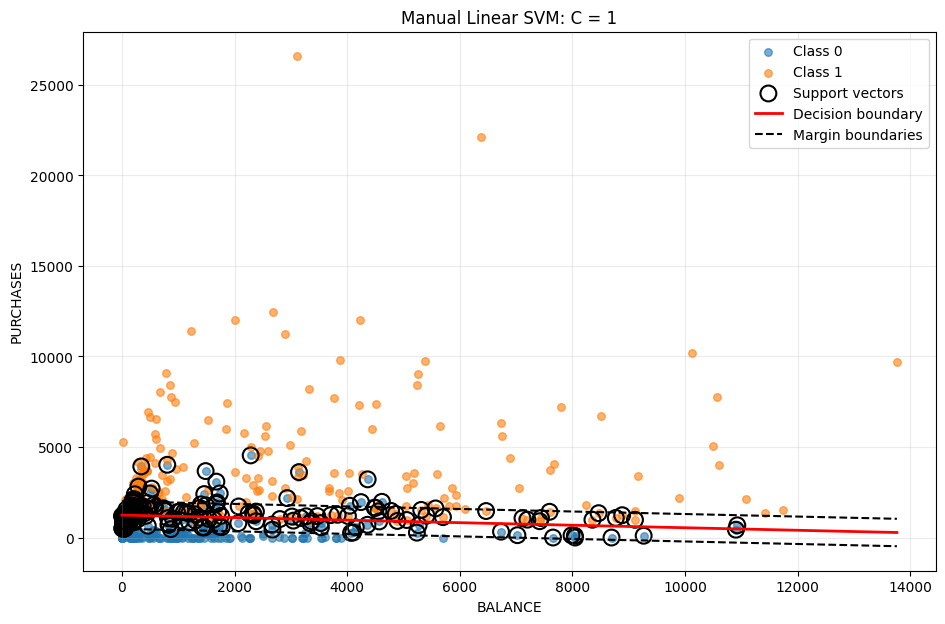

Margin width: 0.5725


In [46]:
w = model["w"]
b = model["b"]
support_mask = model["support_mask"]

x_min = X_raw[:, 0].min()
x_max = X_raw[:, 0].max()

x_line = np.linspace(x_min, x_max, 300)

grid_raw = np.column_stack([
    x_line,
    np.zeros_like(x_line)
])

x_scaled = scaler.transform(grid_raw)

decision_boundary = -(w[0] * x_scaled[:, 0] + b) / w[1]
upper_margin = -(w[0] * x_scaled[:, 0] + b - 1) / w[1]
lower_margin = -(w[0] * x_scaled[:, 0] + b + 1) / w[1]

y_boundary = scaler.inverse_transform(
    np.column_stack([x_scaled[:, 0], decision_boundary])
)[:, 1]

y_upper = scaler.inverse_transform(
    np.column_stack([x_scaled[:, 0], upper_margin])
)[:, 1]

y_lower = scaler.inverse_transform(
    np.column_stack([x_scaled[:, 0], lower_margin])
)[:, 1]

plt.figure(figsize=(11, 7))

plt.scatter(
    X_raw[y == -1, 0],
    X_raw[y == -1, 1],
    label="Class 0",
    alpha=0.6,
    s=30
)

plt.scatter(
    X_raw[y == 1, 0],
    X_raw[y == 1, 1],
    label="Class 1",
    alpha=0.6,
    s=30
)

plt.scatter(
    X_raw[support_mask, 0],
    X_raw[support_mask, 1],
    facecolors="none",
    edgecolors="black",
    s=130,
    linewidths=1.5,
    label="Support vectors"
)

plt.plot(
    x_line, y_boundary,
    color="red",
    linewidth=2,
    label="Decision boundary"
)

plt.plot(
    x_line, y_upper,
    color="black",
    linestyle="--",
    label="Margin boundaries"
)

plt.plot(
    x_line, y_lower,
    color="black",
    linestyle="--"
)

plt.xlabel("BALANCE")
plt.ylabel("PURCHASES")
plt.title("Manual Linear SVM: C = 1")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print(f"Margin width: {margin_width:.4f}")

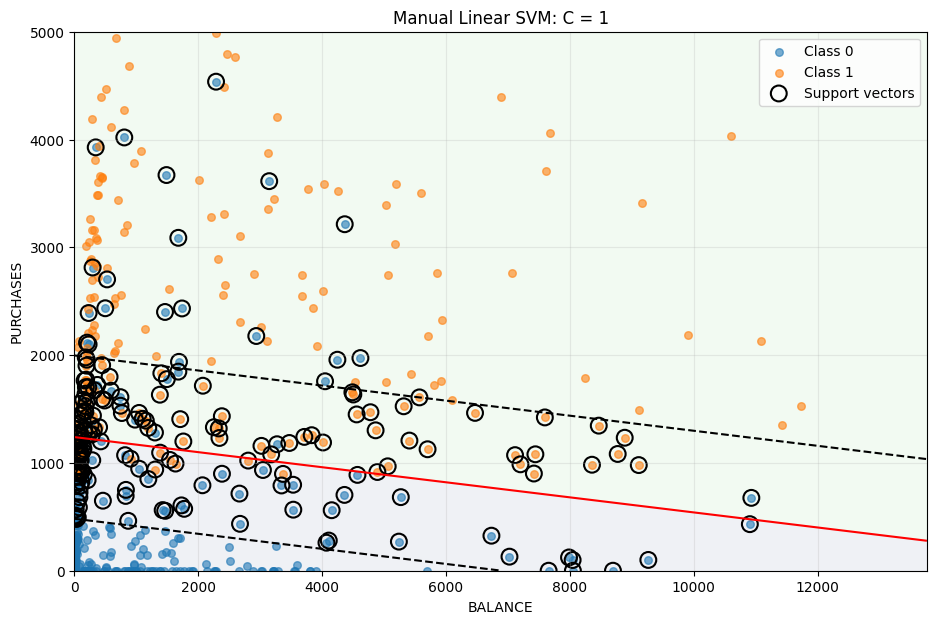

Margin width: 0.5725


In [51]:
w = model["w"]
b = model["b"]

x_min, x_max = X_raw[:, 0].min(), X_raw[:, 0].max()
y_min, y_max = X_raw[:, 1].min(), X_raw[:, 1].max()

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_raw = np.column_stack([xx.ravel(), yy.ravel()])
grid_scaled = scaler.transform(grid_raw)

decision_scores = (grid_scaled @ w + b).reshape(xx.shape)

plt.figure(figsize=(11, 7))

plt.contourf(
    xx, yy, decision_scores,
    levels=[-1e6, 0, 1e6],
    alpha=0.08
)

plt.contour(
    xx, yy, decision_scores,
    levels=[-1, 0, 1],
    colors=["black", "red", "black"],
    linestyles=["--", "-", "--"]
)

plt.scatter(
    X_raw[y == -1, 0], X_raw[y == -1, 1],
    label="Class 0", alpha=0.6, s=30
)

plt.scatter(
    X_raw[y == 1, 0], X_raw[y == 1, 1],
    label="Class 1", alpha=0.6, s=30
)

plt.scatter(
    X_raw[support_mask, 0], X_raw[support_mask, 1],
    facecolors="none", edgecolors="black",
    s=130, linewidths=1.5,
    label="Support vectors"
)

plt.xlabel("BALANCE")
plt.ylabel("PURCHASES")
plt.title("Manual Linear SVM: C = 1")
plt.ylim(0, 5000)

plt.legend()
plt.grid(alpha=0.25)
plt.show()

print(f"Margin width: {2 / np.linalg.norm(w):.4f}")

In [52]:
C_values = [0.1, 1, 10, 100]

models = {}

for C in C_values:
    model = train_manual_svm(X, y, C)
    models[C] = model

    print(f"C = {C}")
    print("Margin width:", round(2 / np.linalg.norm(model["w"]), 4))
    print("Support vectors:", model["support_mask"].sum())
    print("Optimization successful:", model["result"].success)
    print("-" * 40)

C = 0.1
Margin width: 0.8341
Support vectors: 251
Optimization successful: True
----------------------------------------
C = 1
Margin width: 0.5725
Support vectors: 192
Optimization successful: True
----------------------------------------
C = 10
Margin width: 0.5322
Support vectors: 181
Optimization successful: True
----------------------------------------
C = 100
Margin width: 0.5304
Support vectors: 180
Optimization successful: True
----------------------------------------


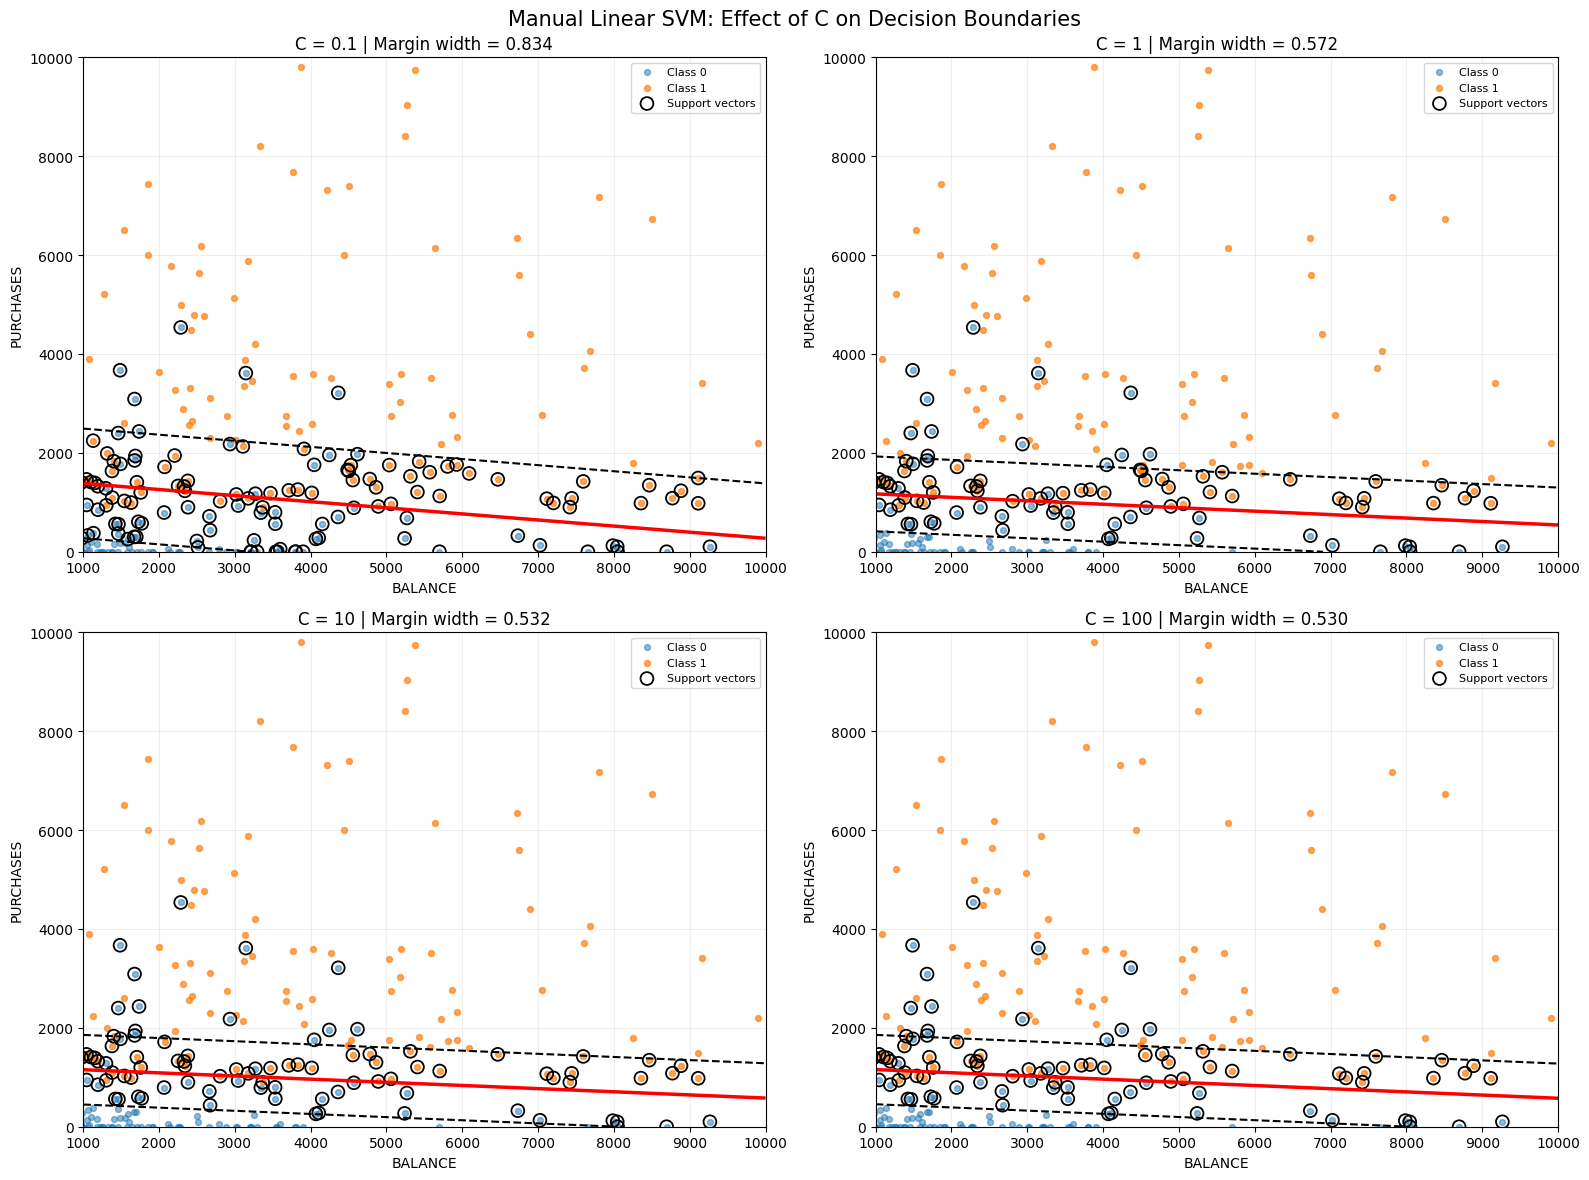

In [53]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

x_min, x_max = 1000, 10000
y_min, y_max = 0, 10000

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

for ax, C in zip(axes.flat, C_values):
    model = models[C]

    grid_raw = np.column_stack([xx.ravel(), yy.ravel()])
    grid_scaled = scaler.transform(grid_raw)

    decision_scores = (
        grid_scaled @ model["w"] + model["b"]
    ).reshape(xx.shape)

    ax.contour(
        xx, yy, decision_scores,
        levels=[-1, 0, 1],
        colors=["black", "red", "black"],
        linestyles=["--", "-", "--"],
        linewidths=[1.5, 2.5, 1.5]
    )

    ax.scatter(
        X_raw[y == -1, 0],
        X_raw[y == -1, 1],
        label="Class 0",
        alpha=0.5,
        s=18
    )

    ax.scatter(
        X_raw[y == 1, 0],
        X_raw[y == 1, 1],
        label="Class 1",
        alpha=0.7,
        s=18
    )

    support = model["support_mask"]

    ax.scatter(
        X_raw[support, 0],
        X_raw[support, 1],
        facecolors="none",
        edgecolors="black",
        s=85,
        linewidths=1.3,
        label="Support vectors"
    )

    margin_width = 2 / np.linalg.norm(model["w"])

    ax.set_title(
        f"C = {C} | Margin width = {margin_width:.3f}"
    )
    ax.set_xlabel("BALANCE")
    ax.set_ylabel("PURCHASES")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

plt.suptitle(
    "Manual Linear SVM: Effect of C on Decision Boundaries",
    fontsize=15
)
plt.tight_layout()
plt.show()

In [54]:
results = []

for C in C_values:
    model = models[C]

    scores = X @ model["w"] + model["b"]
    margin_values = y * scores
    predictions = np.where(scores >= 0, 1, -1)

    results.append({
        "C": C,
        "Margin Width": 2 / np.linalg.norm(model["w"]),
        "Support Vectors": int(model["support_mask"].sum()),
        "Misclassified": int(np.sum(predictions != y)),
        "Inside Margin": int(np.sum(margin_values < 1))
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.round(4).to_string(index=False))

    C  Margin Width  Support Vectors  Misclassified  Inside Margin
  0.1        0.8341              251             72            251
  1.0        0.5725              192             59            190
 10.0        0.5322              181             60            180
100.0        0.5304              180             60            179


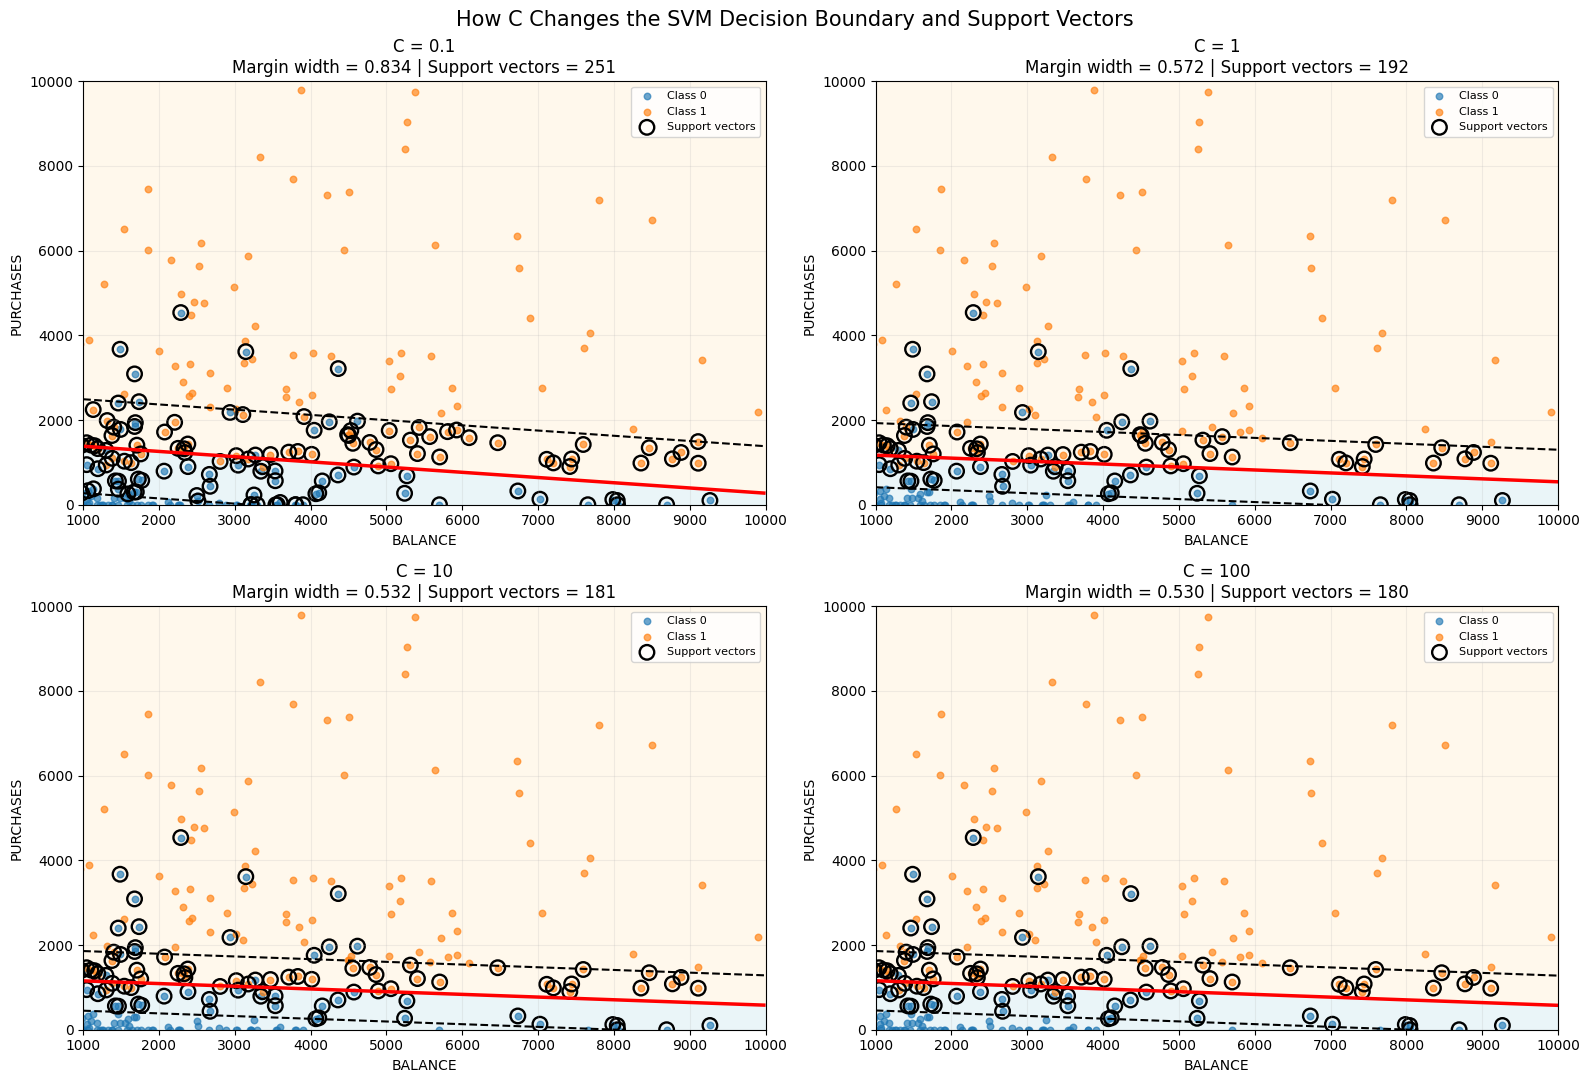

In [55]:
C_values = [0.1, 1, 10, 100]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

x_min, x_max = 1000, 10000
y_min, y_max = 0, 10000

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

for ax, C in zip(axes.flat, C_values):

    model = models[C]
    w = model["w"]
    b = model["b"]

    grid_raw = np.column_stack([
        xx.ravel(),
        yy.ravel()
    ])

    grid_scaled = scaler.transform(grid_raw)

    decision_scores = (
        grid_scaled @ w + b
    ).reshape(xx.shape)

    ax.contourf(
        xx, yy, decision_scores,
        levels=[-1e6, 0, 1e6],
        colors=["lightblue", "moccasin"],
        alpha=0.25
    )

    ax.contour(
        xx, yy, decision_scores,
        levels=[-1, 1],
        colors="black",
        linestyles="--",
        linewidths=1.5
    )

    ax.contour(
        xx, yy, decision_scores,
        levels=[0],
        colors="red",
        linewidths=2.5
    )

    ax.scatter(
        X_raw[y == -1, 0],
        X_raw[y == -1, 1],
        s=22,
        alpha=0.65,
        label="Class 0"
    )

    ax.scatter(
        X_raw[y == 1, 0],
        X_raw[y == 1, 1],
        s=22,
        alpha=0.65,
        label="Class 1"
    )

    support = model["support_mask"]

    ax.scatter(
        X_raw[support, 0],
        X_raw[support, 1],
        s=110,
        facecolors="none",
        edgecolors="black",
        linewidths=1.7,
        label="Support vectors"
    )

    margin_width = 2 / np.linalg.norm(w)

    ax.set_title(
        f"C = {C}\n"
        f"Margin width = {margin_width:.3f} | "
        f"Support vectors = {support.sum()}"
    )

    ax.set_xlabel("BALANCE")
    ax.set_ylabel("PURCHASES")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

plt.suptitle(
    "How C Changes the SVM Decision Boundary and Support Vectors",
    fontsize=15
)

plt.tight_layout()
plt.show()

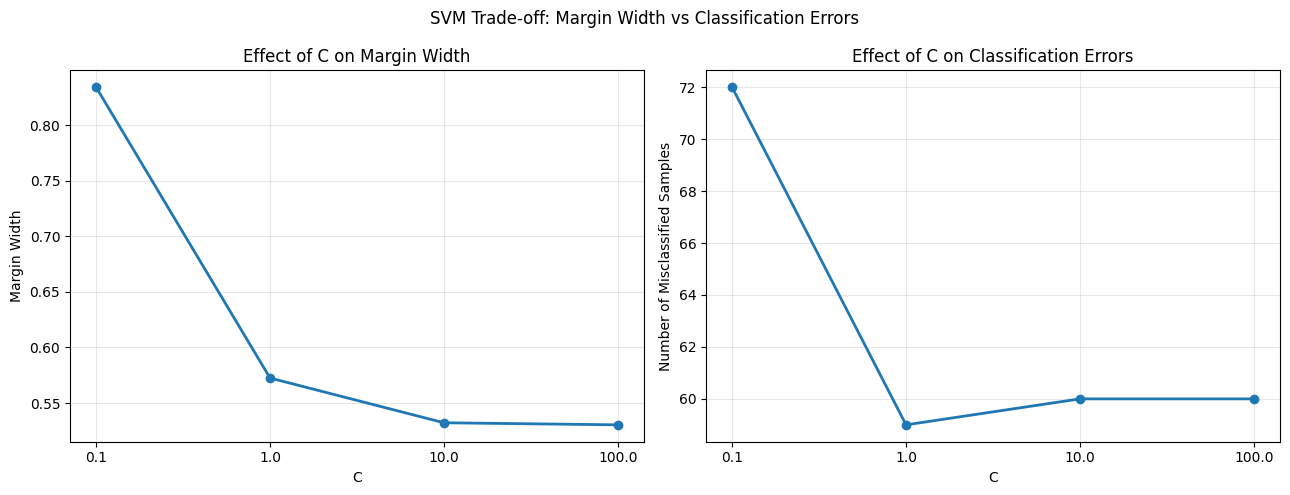

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    comparison_df["C"].astype(str),
    comparison_df["Margin Width"],
    marker="o",
    linewidth=2
)

axes[0].set_title("Effect of C on Margin Width")
axes[0].set_xlabel("C")
axes[0].set_ylabel("Margin Width")
axes[0].grid(alpha=0.3)

axes[1].plot(
    comparison_df["C"].astype(str),
    comparison_df["Misclassified"],
    marker="o",
    linewidth=2
)

axes[1].set_title("Effect of C on Classification Errors")
axes[1].set_xlabel("C")
axes[1].set_ylabel("Number of Misclassified Samples")
axes[1].grid(alpha=0.3)

plt.suptitle("SVM Trade-off: Margin Width vs Classification Errors")
plt.tight_layout()
plt.show()

In [57]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("CC GENERAL.csv")

df = df.replace([np.inf, -np.inf], np.nan)

df = df.dropna(subset=["CREDIT_LIMIT", "PURCHASES"]).copy()

credit_threshold = df["CREDIT_LIMIT"].quantile(0.70)
purchase_threshold = df["PURCHASES"].quantile(0.70)

df["CLASS"] = (
    (df["CREDIT_LIMIT"] >= credit_threshold) &
    (df["PURCHASES"] >= purchase_threshold)
).astype(int)

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["CLASS"].value_counts())

Dataset shape: (8949, 19)

Class distribution:
CLASS
0    7671
1    1278
Name: count, dtype: int64


In [58]:
X = df.drop(columns=["CLASS", "CUST_ID"], errors="ignore")
y = df["CLASS"]

X = X.select_dtypes(include=np.number)

print("Number of features:", X.shape[1])
print("\nFeatures used:")
print(X.columns.tolist())

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)

Number of features: 17

Features used:
['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']

Feature matrix shape: (8949, 17)
Target shape: (8949,)


In [59]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

print("\nTraining percentage:", round(len(X_train) / len(X) * 100, 2))
print("Validation percentage:", round(len(X_val) / len(X) * 100, 2))
print("Testing percentage:", round(len(X_test) / len(X) * 100, 2))

Training set: (5369, 17)
Validation set: (1790, 17)
Testing set: (1790, 17)

Training percentage: 60.0
Validation percentage: 20.0
Testing percentage: 20.0


In [60]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

y_train_svm = np.where(y_train.to_numpy() == 1, 1.0, -1.0)
y_val_svm = np.where(y_val.to_numpy() == 1, 1.0, -1.0)
y_test_svm = np.where(y_test.to_numpy() == 1, 1.0, -1.0)

print("Training features:", X_train_scaled.shape)
print("Validation features:", X_val_scaled.shape)
print("Testing features:", X_test_scaled.shape)

Training features: (5369, 17)
Validation features: (1790, 17)
Testing features: (1790, 17)


In [61]:
def train_primal_svm(X, y, C, epochs=100, batch_size=128, learning_rate=0.001):
    n_samples, n_features = X.shape

    w = np.zeros(n_features, dtype=float)
    b = 0.0

    rng = np.random.default_rng(42)

    for epoch in range(epochs):
        indices = rng.permutation(n_samples)
        current_lr = learning_rate / (1 + 0.02 * epoch)

        for start in range(0, n_samples, batch_size):
            batch_indices = indices[start:start + batch_size]

            X_batch = X[batch_indices]
            y_batch = y[batch_indices]

            margins = y_batch * (X_batch @ w + b)
            violating = margins < 1

            grad_w = w.copy()
            grad_b = 0.0

            if np.any(violating):
                grad_w -= C * np.mean(
                    y_batch[violating, None] * X_batch[violating],
                    axis=0
                )
                grad_b -= C * np.mean(y_batch[violating])

            w -= current_lr * grad_w
            b -= current_lr * grad_b

    return {
        "w": w,
        "b": b,
        "C": C
    }

In [62]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

C_values = [0.1, 1, 10, 100]

models = {}
validation_results = []

for C in C_values:
    model = train_primal_svm(
        X_train_scaled,
        y_train_svm,
        C=C,
        epochs=100,
        batch_size=128,
        learning_rate=0.001
    )

    models[C] = model

    validation_scores = (
        X_val_scaled @ model["w"] + model["b"]
    )

    validation_predictions = (
        validation_scores >= 0
    ).astype(int)

    y_val_binary = y_val.to_numpy()

    validation_results.append({
        "C": C,
        "Accuracy": accuracy_score(
            y_val_binary, validation_predictions
        ),
        "Precision": precision_score(
            y_val_binary, validation_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_binary, validation_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_binary, validation_predictions, zero_division=0
        )
    })

validation_df = pd.DataFrame(validation_results)

print(validation_df.round(4).to_string(index=False))

    C  Accuracy  Precision  Recall  F1-score
  0.1    0.9034     0.6722  0.6328    0.6519
  1.0    0.8983     0.8246  0.3672    0.5081
 10.0    0.9173     0.7727  0.5977    0.6740
100.0    0.9196     0.7718  0.6211    0.6883


In [63]:
best_row = validation_df.loc[validation_df["F1-score"].idxmax()]
best_C = best_row["C"]
best_model = models[best_C]

print("Best C:", best_C)
print("Validation accuracy:", round(best_row["Accuracy"], 4))
print("Validation precision:", round(best_row["Precision"], 4))
print("Validation recall:", round(best_row["Recall"], 4))
print("Validation F1-score:", round(best_row["F1-score"], 4))

Best C: 100.0
Validation accuracy: 0.9196
Validation precision: 0.7718
Validation recall: 0.6211
Validation F1-score: 0.6883


In [66]:

test_scores = X_test_scaled @ best_model["w"] + best_model["b"]
test_predictions = (test_scores >= 0).astype(int)

y_test_binary = y_test.to_numpy()

print("Selected C:", best_C)
print("\nTest Set Results")
print("Accuracy:", round(accuracy_score(y_test_binary, test_predictions), 4))
print("Precision:", round(precision_score(y_test_binary, test_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test_binary, test_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test_binary, test_predictions, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test_binary, test_predictions, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test_binary, test_predictions))


Selected C: 100.0

Test Set Results
Accuracy: 0.9196
Precision: 0.7761
Recall: 0.6118
F1-score: 0.6842

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.97      0.95      1535
           1       0.78      0.61      0.68       255

    accuracy                           0.92      1790
   macro avg       0.86      0.79      0.82      1790
weighted avg       0.91      0.92      0.92      1790

Confusion Matrix:
[[1490   45]
 [  99  156]]


In [67]:

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

logistic_test_predictions = logistic_model.predict(X_test_scaled)

print("Logistic Regression baseline trained successfully.")


Logistic Regression baseline trained successfully.


In [68]:

svm_test_scores = X_test_scaled @ best_model["w"] + best_model["b"]
svm_test_predictions = (svm_test_scores >= 0).astype(int)

y_test_binary = y_test.to_numpy()

comparison_results = []

models_to_compare = {
    "Manual Linear SVM": svm_test_predictions,
    "Logistic Regression": logistic_test_predictions
}

for model_name, predictions in models_to_compare.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_binary, predictions),
        "Precision": precision_score(
            y_test_binary, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_binary, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test_binary, predictions, zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_results)

print(comparison_df.round(4).to_string(index=False))


              Model  Accuracy  Precision  Recall  F1-score
  Manual Linear SVM    0.9196     0.7761  0.6118    0.6842
Logistic Regression    0.9173     0.7488  0.6314    0.6851


In [69]:

best_model_name = comparison_df.loc[
    comparison_df["F1-score"].idxmax(), "Model"
]

print("Model with the highest test F1-score:", best_model_name)


Model with the highest test F1-score: Logistic Regression


In [70]:

feature_weights = pd.DataFrame({
    "Feature": X.columns,
    "Weight": best_model["w"]
})

feature_weights["Absolute Weight"] = feature_weights["Weight"].abs()

top_10_weights = feature_weights.sort_values(
    by="Absolute Weight",
    ascending=False
).head(10)

print("Top 10 Features by Absolute SVM Weight:")
print(top_10_weights.round(4).to_string(index=False))


Top 10 Features by Absolute SVM Weight:
                         Feature  Weight  Absolute Weight
                    CREDIT_LIMIT  1.0694           1.0694
                       PURCHASES  0.4705           0.4705
                ONEOFF_PURCHASES  0.3985           0.3985
          INSTALLMENTS_PURCHASES  0.3951           0.3951
      ONEOFF_PURCHASES_FREQUENCY  0.2550           0.2550
             PURCHASES_FREQUENCY  0.2492           0.2492
PURCHASES_INSTALLMENTS_FREQUENCY  0.1783           0.1783
                        PAYMENTS -0.1410           0.1410
          CASH_ADVANCE_FREQUENCY  0.0939           0.0939
                         BALANCE -0.0669           0.0669


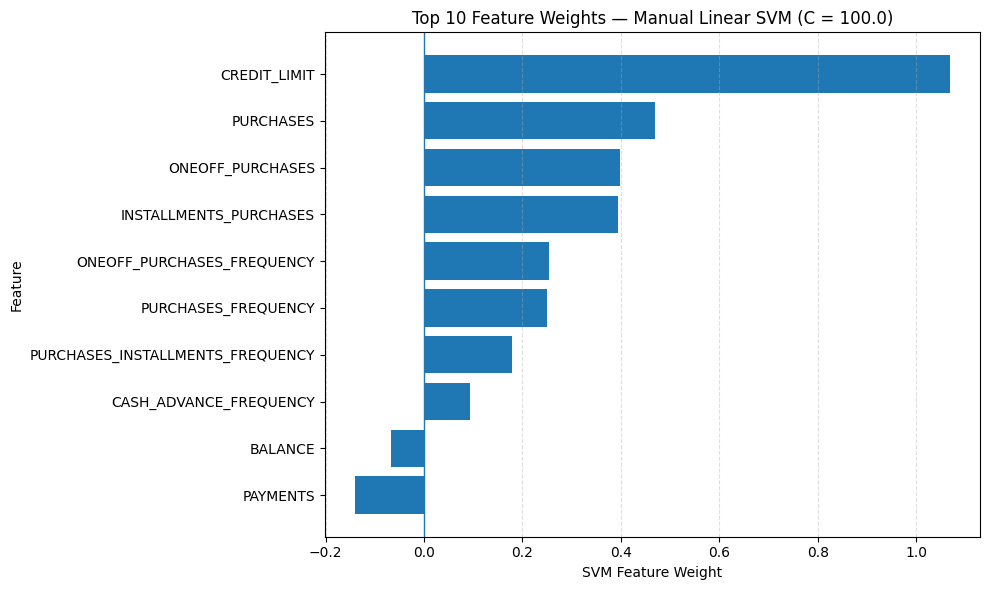

In [71]:

import matplotlib.pyplot as plt

plot_data = top_10_weights.sort_values(
    by="Weight",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Feature"],
    plot_data["Weight"]
)

plt.axvline(0, linewidth=1)
plt.xlabel("SVM Feature Weight")
plt.ylabel("Feature")
plt.title("Top 10 Feature Weights — Manual Linear SVM (C = {})".format(best_C))
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [72]:

train_scores = X_train_scaled @ best_model["w"] + best_model["b"]

train_labels_svm = np.where(
    y_train.to_numpy() == 1, 1, -1
)

margin_values = train_labels_svm * train_scores

borderline_mask = margin_values <= 1.05

borderline_indices = X_train.index[borderline_mask]

borderline_customers = df.loc[borderline_indices].copy()

borderline_customers["SVM Decision Score"] = train_scores[borderline_mask]
borderline_customers["Margin Value"] = margin_values[borderline_mask]
borderline_customers["Predicted Class"] = (
    train_scores[borderline_mask] >= 0
).astype(int)

borderline_customers["Actual Class"] = y_train.loc[
    borderline_indices
].to_numpy()

print("Total training customers:", len(X_train))
print("Borderline customers:", len(borderline_customers))
print(
    "Percentage borderline:",
    round(len(borderline_customers) / len(X_train) * 100, 2),
    "%"
)

print("\nFirst 10 Borderline Customers:")
print(
    borderline_customers[
        [
            "CUST_ID",
            "CLASS",
            "Predicted Class",
            "SVM Decision Score",
            "Margin Value"
        ]
    ].head(10).round(4).to_string(index=False)
)


Total training customers: 5369
Borderline customers: 902
Percentage borderline: 16.8 %

First 10 Borderline Customers:
CUST_ID  CLASS  Predicted Class  SVM Decision Score  Margin Value
 C13767      1                0             -0.0976       -0.0976
 C15116      0                0             -0.9479        0.9479
 C12795      1                1              0.2515        0.2515
 C10430      1                1              0.4200        0.4200
 C13816      1                1              0.1973        0.1973
 C15719      1                1              0.0841        0.0841
 C16579      0                1              0.2081       -0.2081
 C10469      1                1              0.0067        0.0067
 C13195      0                1              1.4595       -1.4595
 C17026      0                0             -0.7519        0.7519


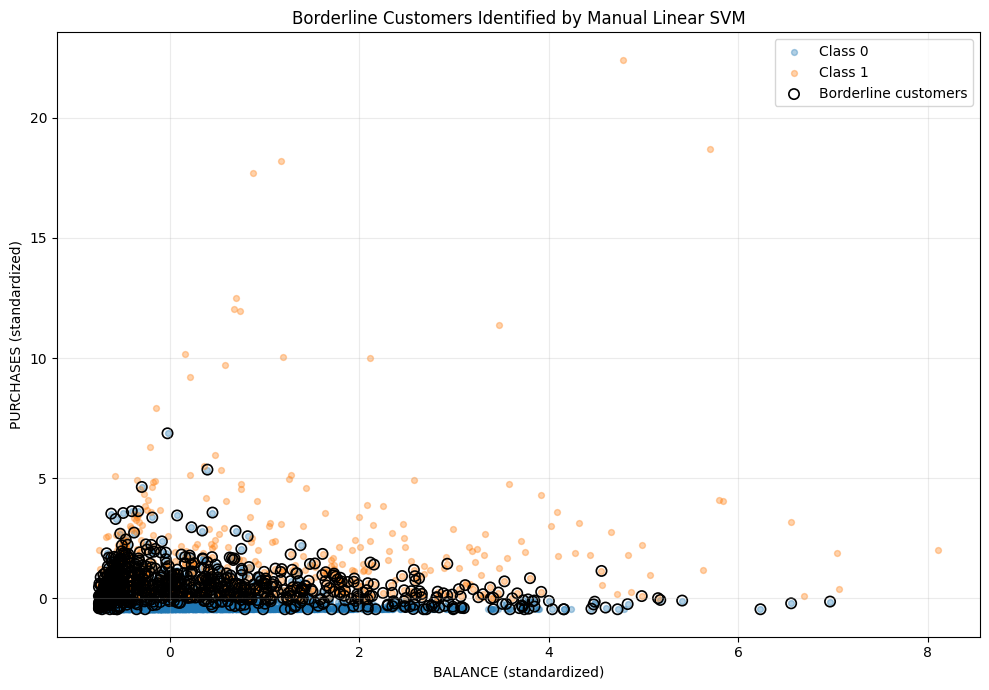

In [74]:

import matplotlib.pyplot as plt

feature_x = "BALANCE"
feature_y = "PURCHASES"

x_position = X.columns.get_loc(feature_x)
y_position = X.columns.get_loc(feature_y)

train_plot = pd.DataFrame({
    "BALANCE": X_train_scaled[:, x_position],
    "PURCHASES": X_train_scaled[:, y_position],
    "Actual Class": y_train.to_numpy(),
    "Margin Value": margin_values
})

train_plot["Borderline"] = train_plot["Margin Value"] <= 1.05

plt.figure(figsize=(10, 7))

for class_value, class_name in [(0, "Class 0"), (1, "Class 1")]:
    class_data = train_plot[train_plot["Actual Class"] == class_value]

    plt.scatter(
        class_data["BALANCE"],
        class_data["PURCHASES"],
        s=18,
        alpha=0.35,
        label=class_name
    )

borderline_data = train_plot[train_plot["Borderline"]]

plt.scatter(
    borderline_data["BALANCE"],
    borderline_data["PURCHASES"],
    s=55,
    facecolors="none",
    edgecolors="black",
    linewidths=1.2,
    label="Borderline customers"
)

plt.xlabel("BALANCE (standardized)")
plt.ylabel("PURCHASES (standardized)")
plt.title("Borderline Customers Identified by Manual Linear SVM")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
